# Imports

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

# Exploring Company CSV

In [9]:
files = glob.glob("./data/*.csv")

print("Total CSV files:", len(files))

for file in files[:10]:
    print(os.path.basename(file))

Total CSV files: 372
ACLBSL.csv
ADBL.csv
AHL.csv
AHPC.csv
AKJCL.csv
AKPL.csv
ALBSL.csv
ALICL.csv
ANLB.csv
APHL.csv


# Getting column information

In [ ]:
all_data = []

for file in files:
    company_name = os.path.basename(file).replace(".csv", "")
    company_df = pd.read_csv(file)
    company_df["company"] = company_name
    all_data.append(company_df)

df = pd.concat(all_data, ignore_index=True)
df["published_date"] = pd.to_datetime(df["published_date"])
df = df.sort_values(["company", "published_date"]).reset_index(drop=True)

In [12]:
print("Rows:", len(df))
print("Companies:", df["company"].nunique())

print("\nDate range:")
print(df["published_date"].min())
print(df["published_date"].max())

print("\nColumns:")
print(df.columns.tolist())
df.head(10)
df.tail(10)

Rows: 510768
Companies: 372

Date range:
1995-07-20 00:00:00
2026-09-18 00:00:00

Columns:
['published_date', 'open', 'high', 'low', 'close', 'per_change', 'traded_quantity', 'traded_amount', 'status', 'company']


,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,company
510758,2026-09-03,562.0,569.8,548.0,562.0,-0.35,16837.0,9324981.9,0,YMHL
510759,2026-09-07,550.0,581.9,550.0,560.0,-0.36,11530.0,6429147.8,1,YMHL
510760,2026-09-09,557.0,566.5,551.0,564.9,0.88,12981.0,7273873.6,1,YMHL
510761,2026-09-10,549.0,564.9,540.4,559.0,-1.04,14529.0,8037538.2,1,YMHL
510762,2026-09-11,548.0,560.0,543.1,555.1,-0.70,11324.0,6271702.3,1,YMHL
510763,2026-09-14,555.1,567.9,552.9,562.0,1.24,19538.0,10967322.3,1,YMHL
510764,2026-09-15,580.0,599.0,552.0,565.0,0.53,34064.0,19309985.5,-1,YMHL
510765,2026-09-16,593.2,593.2,550.0,555.0,-1.77,20220.0,11274617.0,-1,YMHL
510766,2026-09-17,555.0,564.0,550.0,555.0,0.00,22866.0,12706727.1,0,YMHL
510767,2026-09-18,555.0,590.0,550.5,589.4,6.20,73428.0,42035889.4,1,YMHL


# Data per company

In [14]:
company_counts = (df.groupby("company").size().sort_values(ascending=False))
company_counts.head(20)

company
CHCL      4462
CZBIL     3912
BPCL      3762
AHPC      3762
ADBL      3662
ALICL     3612
NTC       3522
SCB       3512
SBI       3512
EBL       3512
NABIL     3512
PCBL      3512
SBL       3362
NLIC      3362
KBL       3320
JBBL      3312
SANIMA    3312
MNBBL     3311
LICN      3262
NLICL     3261
dtype: int64

# Visualization

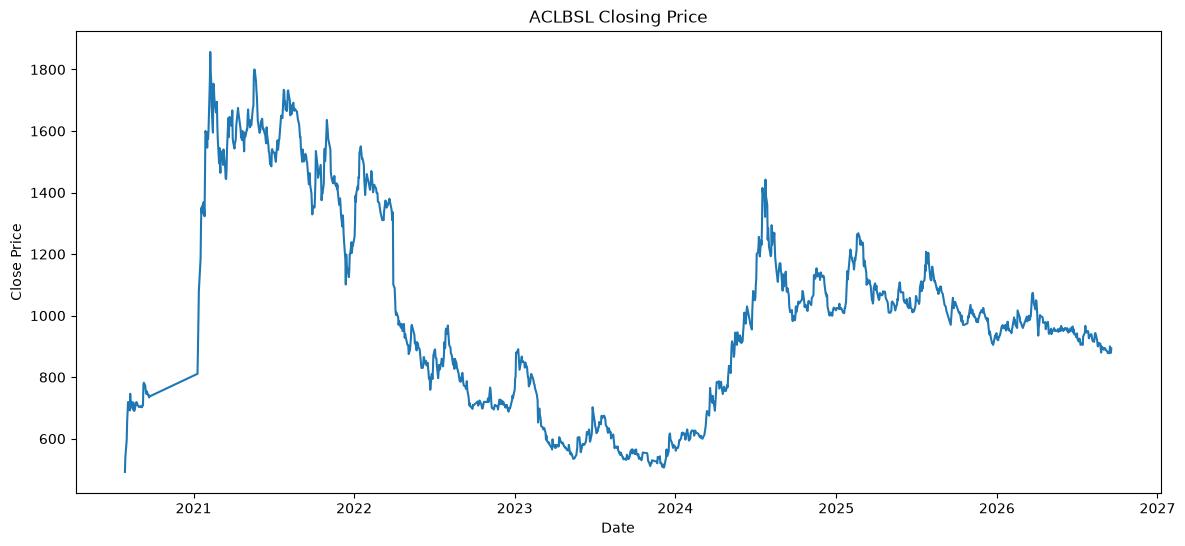

In [17]:
company = "ACLBSL"

company_df = df[df["company"] == company].copy()

plt.figure(figsize=(14, 6))

plt.plot(company_df["published_date"],company_df["close"])
plt.title(f"{company} Closing Price")
plt.xlabel("Date")
plt.ylabel("Close Price")

plt.show()